# 06 - Regressão: Regressão Linear Múltipla, SVR, Bayesian Ridge e Rede Neural

Este notebook utiliza diretamente a classe **`Regression`** de `src/regression.py`, seguindo a mesma estrutura de `01_preparação_clustering.ipynb` / `02_clustering.ipynb` e o roteiro de `aulas_teoricas/07-aula-09-04-treinamento_regressão_2026-07-28.ipynb`.

**Por que criamos um alvo contínuo sintético chamado `PEV`?**
1. O banco de dados `db/Follow_Up_Dissertação.xlsx` contém variáveis genotípicas (categóricas) e desfechos clínicos binários (`Recidiva`), não possuindo uma variável clínica contínua.
2. Além disso, a classe pronta `Regression` (`src/regression.py`) referencia de forma fixa a coluna alvo **`"IFN-γ"`** (`self.X = df.drop("IFN-γ", axis=1)` e `self.y = df["IFN-γ"]`).
3. Por isso, geramos uma **Pontuação Contínua Sintética de Risco Genético (PEV)** baseada nos grupos funcionais de genes do próprio dataset somada a um ruído normal aleatório ($\varepsilon \sim \mathcal{N}(0, 1{,}5^2)$, com `seed=42`) e a armazenamos na coluna `PEV`.

**Algoritmos testados pela classe `Regression` (`src/regression.py`):**

| Código em `regress()` | Algoritmo | Ideia principal |
|---|---|---|
| `"regressor"` | Multiple Linear Regression (`LinearRegression`) | Combinação linear das variáveis selecionadas |
| `"svm"` | Support Vector Regression (`SVR`) | Regressão por vetores de suporte (kernel linear ou RBF) |
| `"bayesian_ridge"` | Bayesian Ridge (`BayesianRidge`) | Regressão linear bayesiana com regularização $L_2$ automática |
| `"neural_network"` | Rede Neural (`KerasRegressor` / `Sequential`) | MLP densa (64 $\to$ 32 $\to$ 1) com `EarlyStopping` e `RandomizedSearchCV` |

**O que `Regression.regress()` executa internamente:**
1. Monta um `Pipeline` com `ColumnTransformer` (`StandardScaler` + `OneHotEncoder`) $\to$ `VarianceThreshold` $\to$ `SelectKBest(f_regression)` $\to$ estimador.
2. Executa `GridSearchCV` (ou `RandomizedSearchCV` para a Rede Neural) com `KFold(n_splits=5, shuffle=True, random_state=42)`.
3. Exibe os melhores hiperparâmetros, a tabela de variáveis selecionadas, o gráfico `jointplot` (Observado $\times$ Predito) e retorna `(metricas, y_pred)` contendo **R Spearman**, **R p-value**, **R2**, **MAE**, **RMSE** e **MAPE**.

## 0. Importações e Configuração de Avisos

In [23]:
import os

# Garantir que o diretório de trabalho seja a pasta do projeto
try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

import logging

# 1. Silencia avisos da camada nativa (C++) do TensorFlow e subprocessos Python
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONWARNINGS"] = "ignore"

# 2. Silencia avisos nativos do Python
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# 3. Silencia loggers do TensorFlow e Keras (usados pelo modelo 'neural_network' de src/regression.py)
import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [24]:
# Carregamento e persistência de dados
from joblib import load, dump

# Processamento de dados
import numpy as np
import pandas as pd

# Divisão de dados, validação cruzada e métricas
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
)

# Testes estatísticos (mesmos utilizados na aula teórica de regressão)
from scipy.stats import (
    spearmanr,
    ks_2samp,
    ttest_ind,
    mannwhitneyu,
    levene,
)

# Visualização
import seaborn as sns
import matplotlib.pyplot as plt

# Objeto pronto de regressão fornecido em src/
from src.regression import Regression

## 1. Carregar (ou Preparar) os Dados para Regressão

Carregamos os dados gerados pelo `05_preparação_regressão.ipynb` (`data/04_df_train`, `data/04_df_valid`, `data/04_df_test`).

In [25]:
if (
    os.path.exists("data/04_df_train")
    and os.path.exists("data/04_df_valid")
    and os.path.exists("data/04_df_test")
):
    # Carrega os conjuntos já preparados no 05_preparação_regressão.ipynb
    df_train = load("data/04_df_train")
    df_valid = load("data/04_df_valid")
    df_test = load("data/04_df_test")
    feature_names = load("data/04_feature_names")
    representacao = load("data/04_representacao")
    print(f"✅ Dados carregados de data/04_* (representação: {representacao})")

print(f"Nº de features: {len(feature_names)}")
print(f"df_train: {df_train.shape} | df_valid: {df_valid.shape} | df_test: {df_test.shape}")
df_train.head()

✅ Dados carregados de data/04_* (representação: grupos)
Nº de features: 3
df_train: (131, 4) | df_valid: (44, 4) | df_test: (44, 4)


,Grupo_1,Grupo_2,Grupo_3,PEV
0,6.0,2.0,1.0,47.2594
1,5.0,1.0,3.0,46.5741
2,4.0,2.0,3.0,41.6063
3,4.0,2.0,3.0,38.3353
4,7.0,1.0,1.0,41.2667


In [26]:
# Nomes amigáveis dos algoritmos
algoritmo_1 = "Multiple Linear Regression"
algoritmo_2 = "Suport Vector Machine"
algoritmo_3 = "Bayesian Ridge"
algoritmo_4 = "Neural Network"

MODELOS = {
    "regressor": algoritmo_1,
    "svm": algoritmo_2,
    "bayesian_ridge": algoritmo_3,
    "neural_network": algoritmo_4,
}


def organizar_metricas_regressao(metricas_dict: dict) -> pd.DataFrame:
    """
    Organiza os DataFrames de métricas retornados por Regression.regress()
    no formato longo (metricas, valores, modelo) usado nos gráficos da aula.
    """
    partes = []
    for codigo, df_m in metricas_dict.items():
        df_long = df_m.T.copy().reset_index()
        df_long.columns = ["metricas", "valores"]
        df_long["modelo"] = MODELOS[codigo]
        partes.append(df_long)
    return pd.concat(partes, ignore_index=True)


def plotar_metricas_regressao(df_metricas: pd.DataFrame, titulo: str) -> None:
    """
    Plota as métricas de avaliação de regressão separando métricas de correlação/ajuste
    (R Spearman, R2) das métricas de erro (MAE, RMSE, MAPE) para facilitar a leitura.
    """
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    fig.suptitle(titulo, fontsize=13)

    # Painel 1: R Spearman e R2 (quanto MAIOR e mais próximo de 1, melhor)
    df_ajuste = df_metricas[df_metricas["metricas"].isin(["R Spearman", "R2"])]
    sns.barplot(x="metricas", y="valores", hue="modelo", data=df_ajuste, ax=axes[0])
    axes[0].set_title("Qualidade do Ajuste (maior = melhor)")
    axes[0].set_ylabel("Valor")
    axes[0].set_xlabel("")
    axes[0].axhline(0, color="black", linewidth=0.8)

    # Painel 2: MAE, RMSE e MAPE (quanto MENOR e mais próximo de 0, melhor)
    df_erros = df_metricas[df_metricas["metricas"].isin(["MAE", "RMSE", "MAPE"])]
    sns.barplot(x="metricas", y="valores", hue="modelo", data=df_erros, ax=axes[1])
    axes[1].set_title("Métricas de Erro (menor = melhor)")
    axes[1].set_ylabel("Erro")
    axes[1].set_xlabel("")

    plt.tight_layout()
    plt.show()
    return None

---
## 2. Validação Cruzada e Busca de Hiperparâmetros com `Regression` (Padrão da Aula)

Seguimos inicialmente o fluxo de `07-aula-09-04-treinamento_regressão_2026-07-28.ipynb`: instanciamos `Regression` em cada conjunto (`df_train`, `df_valid`, `df_test`) e executamos `regress()` para os 4 algoritmos.


### 2.1 Treino

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_2
3. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True               True
          num__Grupo_3              True               True


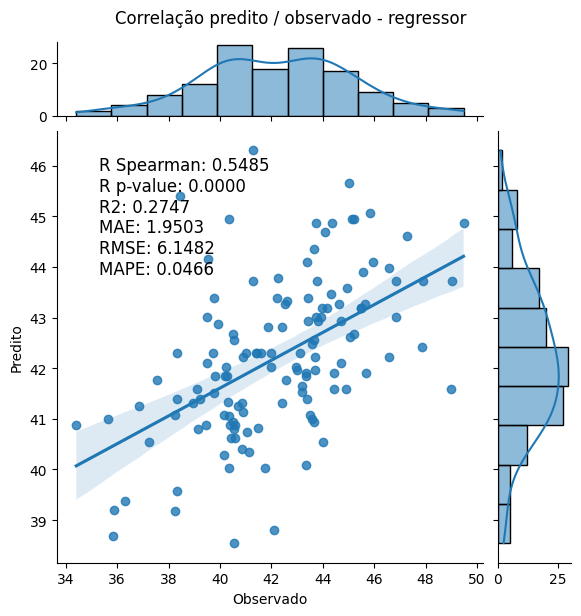

In [27]:
# Instancia o objeto Regression com o conjunto de treino
regressor = Regression(df=df_train)

metricas_train, pred_train = {}, {}

# 1. Regressão Linear Múltipla
metricas_train["regressor"], pred_train["regressor"] = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 1
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_2
3. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True               True
          num__Grupo_3              True               True


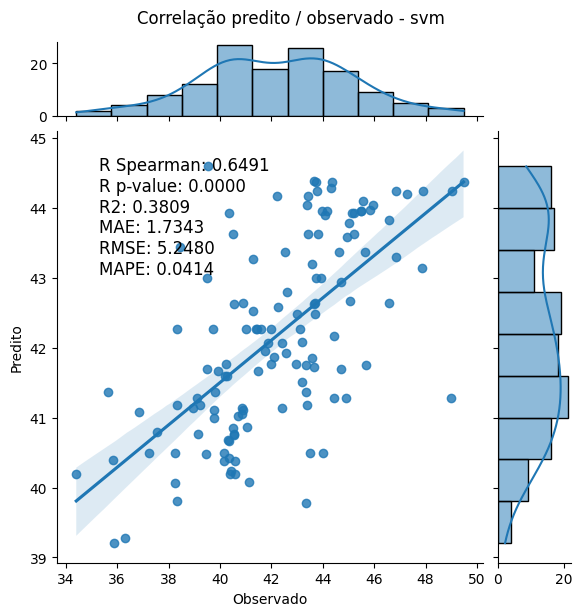

In [28]:
# 2. Support Vector Regression (SVR)
metricas_train["svm"], pred_train["svm"] = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_2
3. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True               True
          num__Grupo_3              True               True


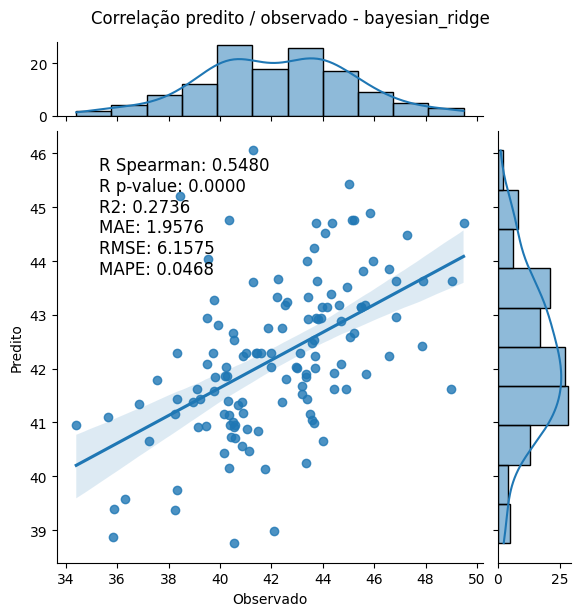

In [29]:
# 3. Bayesian Ridge Regression
metricas_train["bayesian_ridge"], pred_train["bayesian_ridge"] = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 10
nn__batch_size -> 16
nn__activation2 -> tanh
nn__activation1 -> tanh
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True              False


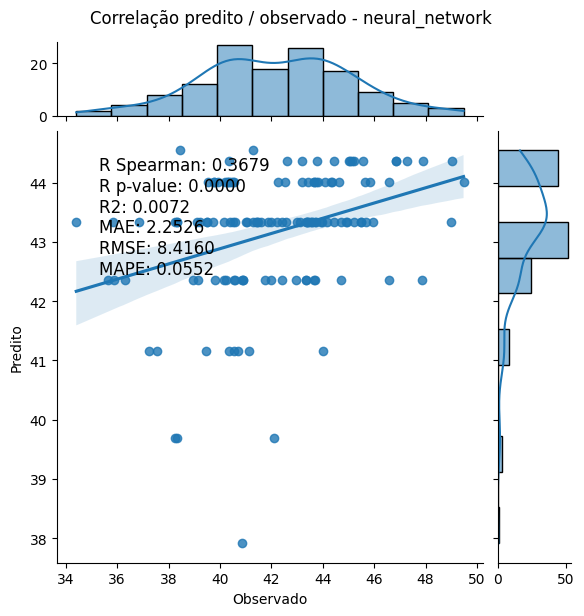

In [30]:
# 4. Rede Neural (KerasRegressor com RandomizedSearchCV e EarlyStopping)
# n_iter_search=5 para manter o tempo de execução rápido
metricas_train["neural_network"], pred_train["neural_network"] = regressor.regress(
    modelo="neural_network", n_iter_search=5
)

metricas,MAE,MAPE,R Spearman,R p-value,R2,RMSE
modelo,,,,,,
Bayesian Ridge,1.9576,0.0468,0.5480,0.0,0.2736,6.1575
Multiple Linear Regression,1.9503,0.0466,0.5485,0.0,0.2747,6.1482
Neural Network,2.2526,0.0552,0.3679,0.0,0.0072,8.4160
Suport Vector Machine,1.7343,0.0414,0.6491,0.0,0.3809,5.2480


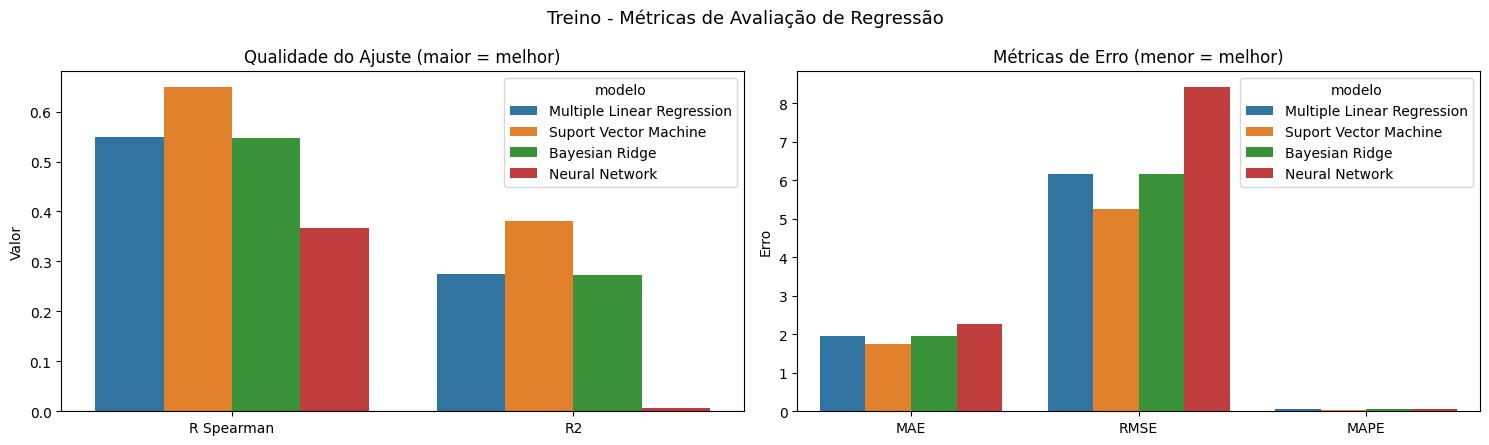

,PEV,Multiple Linear Regression,Suport Vector Machine,Bayesian Ridge,Neural Network
0,47.2594,44.620135,44.190256,44.485545,44.371548
1,46.5741,43.973236,43.828714,43.853729,44.006836
2,41.6063,42.292564,42.263439,42.284179,43.329773
3,38.3353,42.292564,42.263439,42.284179,43.329773
4,41.2667,46.300807,42.518236,46.055095,44.544487


In [31]:
# Organizando e visualizando as métricas de treinamento
df_metricas_train = organizar_metricas_regressao(metricas_train)
display(df_metricas_train.pivot(index="modelo", columns="metricas", values="valores").round(4))

plotar_metricas_regressao(df_metricas_train, "Treino - Métricas de Avaliação de Regressão")

# Salva as predições em uma cópia do DataFrame de treino
df_pred_train = df_train.copy()
for codigo, nome in MODELOS.items():
    df_pred_train[nome] = np.asarray(pred_train[codigo]).ravel()

df_pred_train[["PEV", *MODELOS.values()]].head()

### 2.2 Validação

 VALIDAÇÃO - Multiple Linear Regression
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 1
regressor__fit_intercept -> True
regressor__positive -> True
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True              False


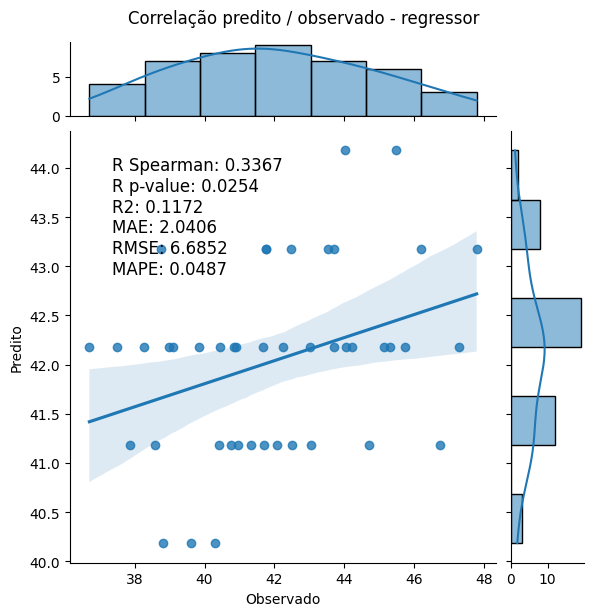

 VALIDAÇÃO - Suport Vector Machine
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 1
svm__C -> 1
svm__epsilon -> 0.01
svm__kernel -> linear
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True              False


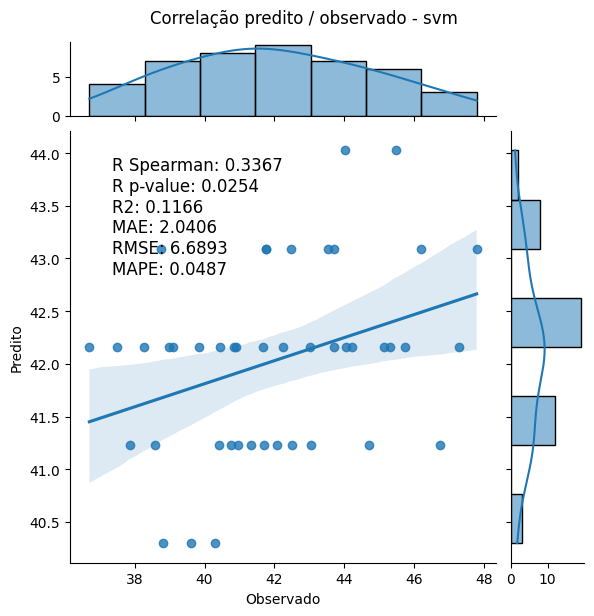

 VALIDAÇÃO - Bayesian Ridge
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 1
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True              False


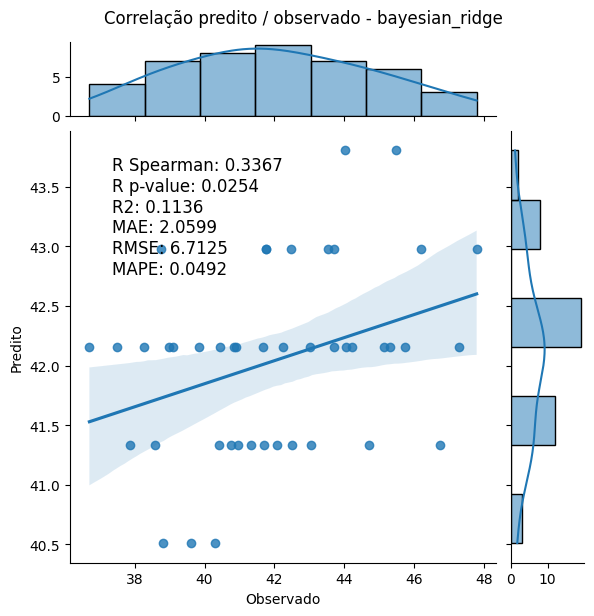

 VALIDAÇÃO - Neural Network
Iniciando o Grid Search com Cross Validation...


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> sigmoid
nn__activation1 -> sigmoid
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True              False


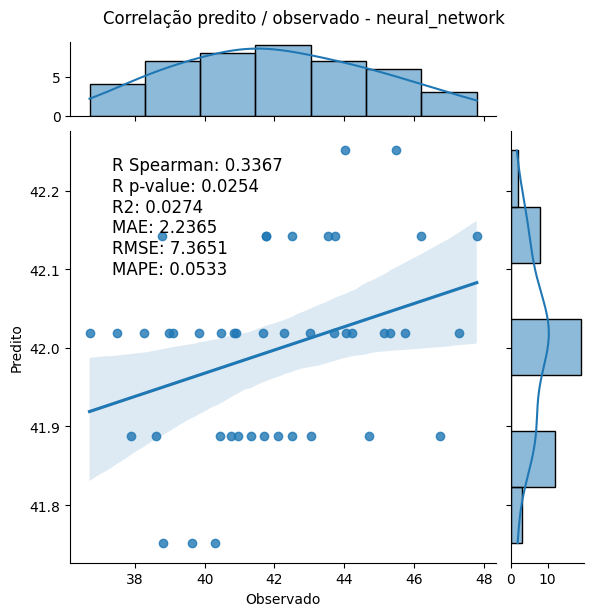

In [32]:
regressor = Regression(df=df_valid)
metricas_valid, pred_valid = {}, {}

for codigo, nome in MODELOS.items():
    print("=" * 70)
    print(f" VALIDAÇÃO - {nome}")
    print("=" * 70)
    if codigo == "neural_network":
        metricas_valid[codigo], pred_valid[codigo] = regressor.regress(modelo=codigo, n_iter_search=5)
    else:
        metricas_valid[codigo], pred_valid[codigo] = regressor.regress(modelo=codigo)

metricas,MAE,MAPE,R Spearman,R p-value,R2,RMSE
modelo,,,,,,
Bayesian Ridge,2.0599,0.0492,0.3367,0.0254,0.1136,6.7125
Multiple Linear Regression,2.0406,0.0487,0.3367,0.0254,0.1172,6.6852
Neural Network,2.2365,0.0533,0.3367,0.0254,0.0274,7.3651
Suport Vector Machine,2.0406,0.0487,0.3367,0.0254,0.1166,6.6893


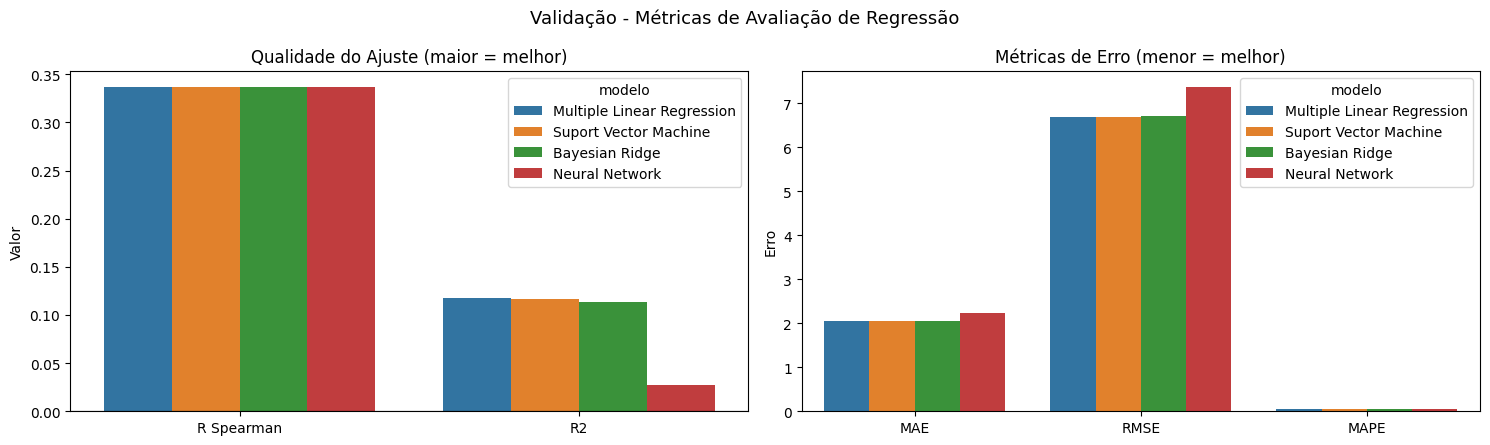

,PEV,Multiple Linear Regression,Suport Vector Machine,Bayesian Ridge,Neural Network
0,43.5356,43.179089,43.092925,42.980375,42.142300
1,43.0424,41.182605,41.230175,41.333627,41.887402
2,41.6774,42.180847,42.161550,42.157001,42.019554
3,41.7617,43.179089,43.092925,42.980375,42.142300
4,36.7013,42.180847,42.161550,42.157001,42.019554


In [33]:
df_metricas_valid = organizar_metricas_regressao(metricas_valid)
display(df_metricas_valid.pivot(index="modelo", columns="metricas", values="valores").round(4))

plotar_metricas_regressao(df_metricas_valid, "Validação - Métricas de Avaliação de Regressão")

df_pred_valid = df_valid.copy()
for codigo, nome in MODELOS.items():
    df_pred_valid[nome] = np.asarray(pred_valid[codigo]).ravel()

df_pred_valid[["PEV", *MODELOS.values()]].head()

### 2.3 Teste

 TESTE - Multiple Linear Regression
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> True
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_2
3. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True               True
          num__Grupo_3              True               True


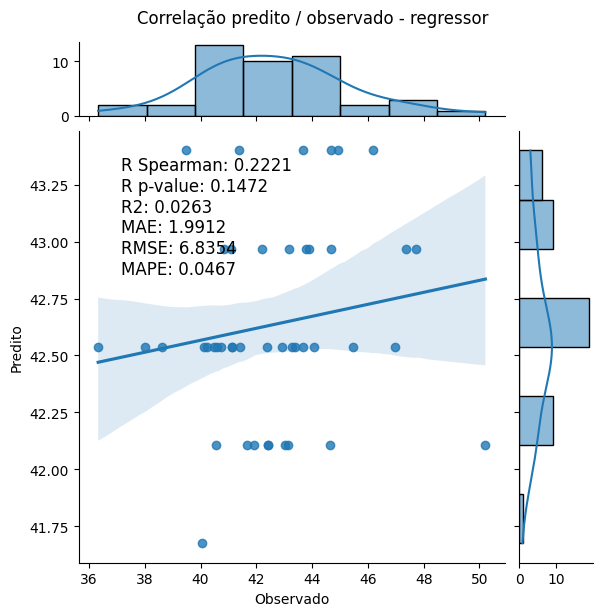

 TESTE - Suport Vector Machine
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 0.1
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True              False
          num__Grupo_3              True               True


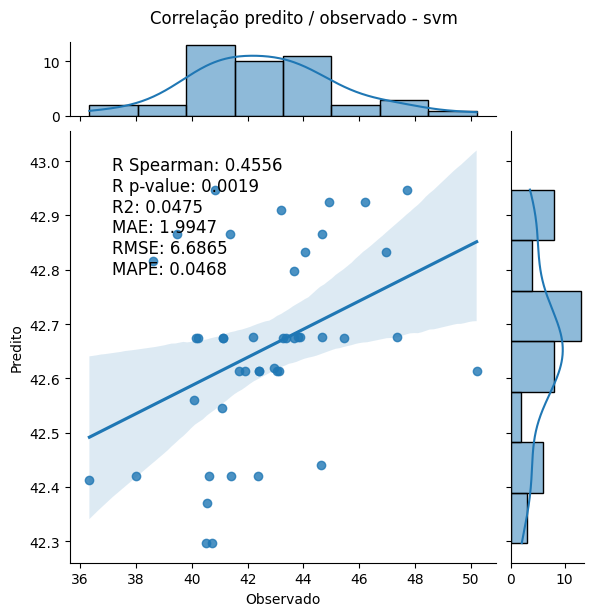

 TESTE - Bayesian Ridge
Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 1e-06
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_1
2. num__Grupo_2
3. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True               True
          num__Grupo_2              True               True
          num__Grupo_3              True               True


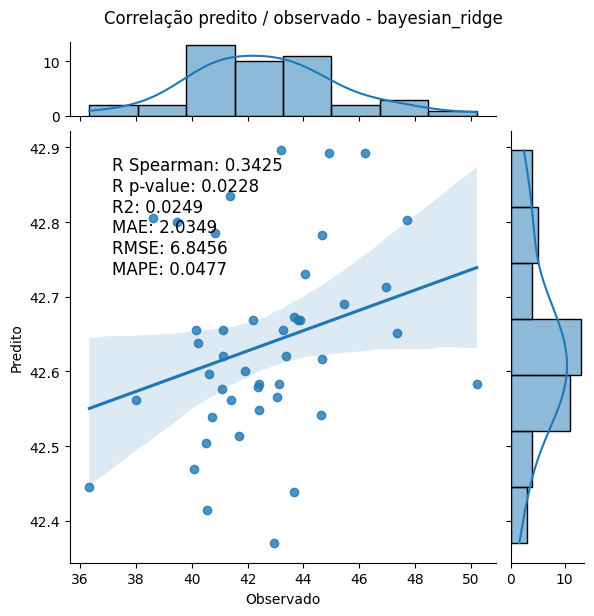

 TESTE - Neural Network
Iniciando o Grid Search com Cross Validation...


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.0001
nn__optimizer -> RMSprop
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> relu
nn__activation1 -> tanh
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Grupo_3

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
          num__Grupo_1              True              False
          num__Grupo_2              True              False
          num__Grupo_3              True               True


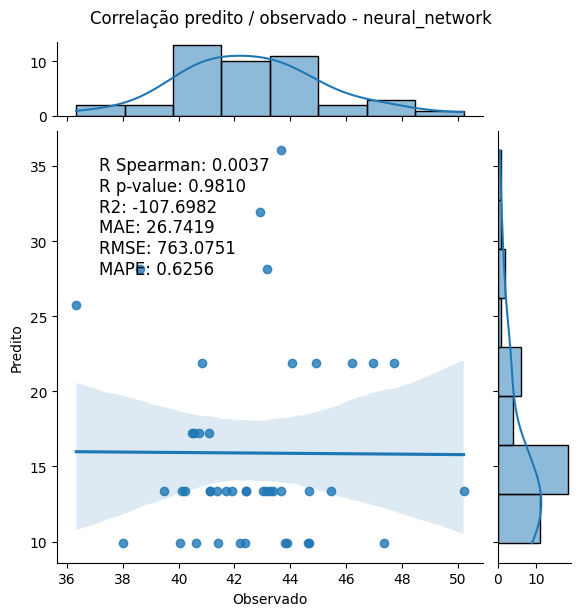

In [34]:
regressor = Regression(df=df_test)
metricas_test, pred_test = {}, {}

for codigo, nome in MODELOS.items():
    print("=" * 70)
    print(f" TESTE - {nome}")
    print("=" * 70)
    if codigo == "neural_network":
        metricas_test[codigo], pred_test[codigo] = regressor.regress(modelo=codigo, n_iter_search=5)
    else:
        metricas_test[codigo], pred_test[codigo] = regressor.regress(modelo=codigo)

metricas,MAE,MAPE,R Spearman,R p-value,R2,RMSE
modelo,,,,,,
Bayesian Ridge,2.0349,0.0477,0.3425,0.0228,0.0249,6.8456
Multiple Linear Regression,1.9912,0.0467,0.2221,0.1472,0.0263,6.8354
Neural Network,26.7419,0.6256,0.0037,0.9810,-107.6982,763.0751
Suport Vector Machine,1.9947,0.0468,0.4556,0.0019,0.0475,6.6865


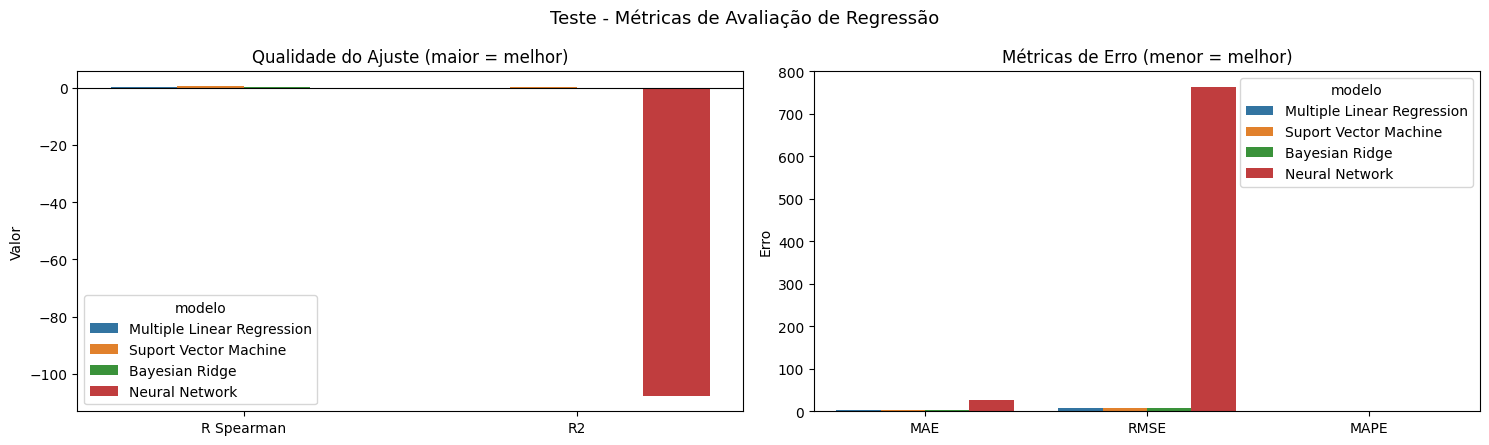

,PEV,Multiple Linear Regression,Suport Vector Machine,Bayesian Ridge,Neural Network
0,40.2193,42.538138,42.674579,42.637534,13.351500
1,44.6804,43.400526,42.865111,42.782094,13.351500
2,42.4072,42.106944,42.614400,42.582693,13.351500
3,47.7061,42.969332,42.947635,42.802799,21.863632
4,38.6111,42.538138,42.816888,42.806065,28.147955


In [35]:
df_metricas_test = organizar_metricas_regressao(metricas_test)
display(df_metricas_test.pivot(index="modelo", columns="metricas", values="valores").round(4))

plotar_metricas_regressao(df_metricas_test, "Teste - Métricas de Avaliação de Regressão")

df_pred_test = df_test.copy()
for codigo, nome in MODELOS.items():
    df_pred_test[nome] = np.asarray(pred_test[codigo]).ravel()

df_pred_test[["PEV", *MODELOS.values()]].head()

---
## 3. Comparação Geral dos Algoritmos

In [36]:
df_metricas_train["conjunto"] = "Treino"
df_metricas_valid["conjunto"] = "Validação"
df_metricas_test["conjunto"] = "Teste"

df_comparacao = pd.concat(
    [df_metricas_train, df_metricas_valid, df_metricas_test], ignore_index=True
)

tabela_comparacao = df_comparacao.pivot_table(
    index="modelo", columns=["conjunto", "metricas"], values="valores"
).reindex(columns=["Treino", "Validação", "Teste"], level=0)

print("=" * 70)
print(" COMPARAÇÃO DOS ALGORITMOS DE REGRESSÃO (Regression.regress)")
print("=" * 70)
display(tabela_comparacao.round(4))

print("\nGuia de interpretação das métricas:")
print("  R Spearman: Correlação monotônica entre observado e predito (-1 a 1, quanto MAIOR melhor)")
print("  R p-value:  Significância estatística da correlação de Spearman (< 0.05 indica correlação significativa)")
print("  R2:         Fração da variância explicada pelo modelo (<= 1, quanto MAIOR melhor)")
print("  MAE:        Erro Absoluto Médio (quanto MENOR melhor)")
print("  RMSE:       Erro Quadrático Médio calculado por src/regression.py (quanto MENOR melhor)")
print("  MAPE:       Erro Percentual Absoluto Médio (quanto MENOR melhor)")

 COMPARAÇÃO DOS ALGORITMOS DE REGRESSÃO (Regression.regress)


conjunto                    Treino                                       \
metricas                       MAE    MAPE R Spearman R p-value      R2   
modelo                                                                    
Bayesian Ridge              1.9576  0.0468     0.5480       0.0  0.2736   
Multiple Linear Regression  1.9503  0.0466     0.5485       0.0  0.2747   
Neural Network              2.2526  0.0552     0.3679       0.0  0.0072   
Suport Vector Machine       1.7343  0.0414     0.6491       0.0  0.3809   

conjunto                           Validação                               \
metricas                      RMSE       MAE    MAPE R Spearman R p-value   
modelo                                                                      
Bayesian Ridge              6.1575    2.0599  0.0492     0.3367    0.0254   
Multiple Linear Regression  6.1482    2.0406  0.0487     0.3367    0.0254   
Neural Network              8.4160    2.2365  0.0533     0.3367    0.0254   
Suport Vector Machine       5.2480    2.0406  0.0487     0.3367    0.0254   

conjunto                                      Teste                     \
metricas                        R2    RMSE      MAE    MAPE R Spearman   
modelo                                                                   
Bayesian Ridge              0.1136  6.7125   2.0349  0.0477     0.3425   
Multiple Linear Regression  0.1172  6.6852   1.9912  0.0467     0.2221   
Neural Network              0.0274  7.3651  26.7419  0.6256     0.0037   
Suport Vector Machine       0.1166  6.6893   1.9947  0.0468     0.4556   

conjunto                                                  
metricas                   R p-value        R2      RMSE  
modelo                                                    
Bayesian Ridge                0.0228    0.0249    6.8456  
Multiple Linear Regression    0.1472    0.0263    6.8354  
Neural Network                0.9810 -107.6982  763.0751  
Suport Vector Machine         0.0019    0.0475    6.6865


Guia de interpretação das métricas:
  R Spearman: Correlação monotônica entre observado e predito (-1 a 1, quanto MAIOR melhor)
  R p-value:  Significância estatística da correlação de Spearman (< 0.05 indica correlação significativa)
  R2:         Fração da variância explicada pelo modelo (<= 1, quanto MAIOR melhor)
  MAE:        Erro Absoluto Médio (quanto MENOR melhor)
  RMSE:       Erro Quadrático Médio calculado por src/regression.py (quanto MENOR melhor)
  MAPE:       Erro Percentual Absoluto Médio (quanto MENOR melhor)


---
## 5. Testes Estatísticos de Hipótese (Treino $\times$ Teste)

Seguindo exatamente a seção final da aula `07-aula-09-04-treinamento_regressão_2026-07-28.ipynb`, aplicamos 4 testes estatísticos para verificar se a distribuição dos valores preditos no **Treino** e no **Teste** é homogênea ($H_0$: distribuições/médias/medianas/variâncias iguais, $p \ge 0{,}05$) ou heterogênea ($H_1$: diferentes, $p < 0{,}05$):
- **Kolmogorov-Smirnov (`ks_2samp`):** compara o formato geral das duas distribuições acumuladas.
- **Teste T de Welch (`ttest_ind`):** compara as **médias**.
- **Mann-Whitney U (`mannwhitneyu`):** compara as **medianas/postos** (não-paramétrico).
- **Teste de Levene (`levene`):** compara as **variâncias** (dispersão).

In [37]:
def testar_hipotese(y_pred_treino: pd.Series, y_pred_teste: pd.Series) -> dict:
    """
    Testa se as previsões no treino e no teste possuem mesma distribuição,
    média, mediana e variância (nível de significância de 5%).
    """
    ks_stat, p_v_ks = ks_2samp(y_pred_treino, y_pred_teste)
    t_stat, p_val_t = ttest_ind(y_pred_treino, y_pred_teste, equal_var=False)
    u_stat, p_val_u = mannwhitneyu(y_pred_treino, y_pred_teste, alternative="two-sided")
    w_stat, p_val_levene = levene(y_pred_treino, y_pred_teste)

    def interpretar(nome_teste, p_valor, stat, alfa=0.05):
        resultado = (
            "DIFERENTES (Rejeita H0)"
            if p_valor < alfa
            else "IGUAIS (Falha ao rejeitar H0)"
        )
        print(
            f"{nome_teste:<25} | estatística: {stat:10.4f} | p-valor: {p_valor:.4f} | Conclusão: {resultado}"
        )

    print("=== Resultados dos Testes Estatísticos ===")
    interpretar("Teste Kolmogorov-Smirnov", p_v_ks, ks_stat)
    interpretar("Teste T (Médias)", p_val_t, t_stat)
    interpretar("Mann-Whitney (Medianas)", p_val_u, u_stat)
    interpretar("Levene (Variâncias)", p_val_levene, w_stat)

    return {
        "KS_p": p_v_ks,
        "Welch_T_p": p_val_t,
        "MannWhitney_p": p_val_u,
        "Levene_p": p_val_levene,
    }


resumo_testes = []
for codigo, nome in MODELOS.items():
    print(f"\nTestando a hipótese para o modelo: {nome}")
    res = testar_hipotese(
        y_pred_treino=df_pred_train[nome],
        y_pred_teste=df_pred_test[nome],
    )
    res["modelo"] = nome
    resumo_testes.append(res)

df_testes_hipotese = pd.DataFrame(resumo_testes).set_index("modelo")
display(df_testes_hipotese.round(4))


Testando a hipótese para o modelo: Multiple Linear Regression
=== Resultados dos Testes Estatísticos ===
Teste Kolmogorov-Smirnov  | estatística:     0.4811 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística:    -2.8205 | p-valor: 0.0054 | Conclusão: DIFERENTES (Rejeita H0)
Mann-Whitney (Medianas)   | estatística:  2179.0000 | p-valor: 0.0156 | Conclusão: DIFERENTES (Rejeita H0)
Levene (Variâncias)       | estatística:    39.1280 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)

Testando a hipótese para o modelo: Suport Vector Machine
=== Resultados dos Testes Estatísticos ===
Teste Kolmogorov-Smirnov  | estatística:     0.5802 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística:    -3.9132 | p-valor: 0.0001 | Conclusão: DIFERENTES (Rejeita H0)
Mann-Whitney (Medianas)   | estatística:  2118.0000 | p-valor: 0.0086 | Conclusão: DIFERENTES (Rejeita H0)
Levene (Variâncias)       | estatística:    

,KS_p,Welch_T_p,MannWhitney_p,Levene_p
modelo,,,,
Multiple Linear Regression,0.0,0.0054,0.0156,0.0
Suport Vector Machine,0.0,0.0001,0.0086,0.0
Bayesian Ridge,0.0,0.0012,0.0110,0.0
Neural Network,0.0,0.0000,0.0000,0.0


## 6. Salvar Resultados

In [38]:
os.makedirs("data", exist_ok=True)

# Resultados do padrão da aula (Regression.regress em cada conjunto)
dump(df_pred_train, "data/04_df_train_resultados_regression")
dump(df_pred_valid, "data/04_df_valid_resultados_regression")
dump(df_pred_test, "data/04_df_test_resultados_regression")
dump(df_comparacao, "data/04_comparacao_regressao")

# Resultados de testes estatísticos
dump(df_testes_hipotese, "data/04_testes_hipotese_regressao")

print("✅ Resultados de regressão salvos com sucesso em data/04_*!")

✅ Resultados de regressão salvos com sucesso em data/04_*!
